# Seminar Assignment 1 - Scheduling with Genetic Algorithms

### LLM logs
Includes inks to chat logs:
- Gemini used for effective claude prompt making:
https://share.gemini.google/i3kobBYSy1mW

- Claude used for writing code based on ideas for Task 1: https://claude.ai/share/212907ce-cb37-407e-bfbe-be0e8cb78a75  
<i>(This code was then restructured and repourposed)</i>

## Task 1

In [1]:
import io, re
import numpy as np
import pygad
from IPython.display import display, Image as IPyImage
from PIL import Image, ImageDraw, ImageFont


### Gene structure
For 1 class:  
$$[classroom,\ teacher,\ start] := [c_0,\ t_0,\ s_0]$$

For $n$ classes:
$$[c_0,\ t_0,\ s_0,\ c_1,\ t_1,\ s_1,\ \dots,\ c_{n-1},\ t_{n-1},\ s_{n-1}]$$
  
It is implemented this way, so we can work with <i>PyGAD</i>.

### Fitness Function

The fitness function is going to be an inverse function of the penalty function:

fitness function $:= F$  
penalty function $:= P$  
$+ 1$ for avoiding division with zero

$$F = \frac{1}{1 + P}$$

It will prioritize no overlaps between classrooms ($P_{\text{classroom}}$), teachers ($P_{\text{teacher}}$), and classes ($P_{\text{class}}$),  
while also making sure that it's inside the correct time window $08:00 - 16:00$ ($P_{\text{window}}$) and a class has the correct teacher ($P_{\text{correct\_teacher}}$). 

That means that the penalties for overlaps will be higher by a constant $c$ (which will be determined with testing):

$$P = c \cdot \left( P_{\text{classroom}} + P_{\text{teacher}} + P_{\text{class}} \right) + P_{\text{window}} + P_{\text{correct\_teacher}}$$

In [2]:
def _parse_value(tok):
    tok = tok.strip()
    try:
        return int(tok)
    except ValueError:
        return tok.strip("'\"")

def parse_file(path):
    out = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            m = re.match(r"^(.+?)\s*\[(.*)\]\s*$", line)
            if not m:
                raise ValueError(f"Bad line in {path}: {line!r}")
            key = m.group(1).strip()
            vals = [_parse_value(v) for v in m.group(2).split(",") if v.strip()]
            out[key] = vals
    return out


class ProblemData:
    DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri"]

    def __init__(self, classes_path, classrooms_path, teachers_path,
                 num_days=5, day_start=8, day_end=16):
        classes = parse_file(classes_path)
        classrooms = parse_file(classrooms_path)
        teachers = parse_file(teachers_path)

        self.num_days, self.day_start, self.day_end = num_days, day_start, day_end
        self.hours_per_day = day_end - day_start
        self.num_slots = num_days * self.hours_per_day     # s in [0, num_slots)

        # flattened lectures: (lecture_id, subject, duration) - fixed order, fixed length n
        self.lectures = []
        for subject, durations in classes.items():
            for d in durations:
                self.lectures.append((len(self.lectures), subject, int(d)))
        self.n = len(self.lectures)

        self.classroom_names = list(classrooms.keys())
        self.classroom_hours = [tuple(classrooms[k][:2]) for k in self.classroom_names]
        self.teacher_names = list(teachers.keys())
        self.teacher_subjects = [set(map(str, teachers[k])) for k in self.teacher_names]
        self.subjects = list(classes.keys())

        self.num_classrooms = len(self.classroom_names)
        self.num_teachers = len(self.teacher_names)

    def gene_space(self):
        space = []
        for _ in range(self.n):
            space.append(list(range(self.num_classrooms)))
            space.append(list(range(self.num_teachers)))
            space.append(list(range(self.num_slots)))
        return space

In [ ]:
def _overlap(a_start, a_end, b_start, b_end):
    return max(0, min(a_end, b_end) - max(a_start, b_start))


class Schedule:
    def __init__(self, problem, assignments):
        """assignments: list of dicts, one per lecture, in lecture_id order."""
        self.problem = problem
        self.assignments = assignments

    # ---- encoding / decoding ----
    @classmethod
    def from_gene(cls, gene, problem_data):
        p = problem_data
        gene = np.asarray(gene).astype(int)
        assert len(gene) == 3 * p.n, "gene length must be 3n"
        asg = []
        for i, (lid, subject, dur) in enumerate(p.lectures):
            c, t, s = (int(x) for x in gene[3*i:3*i+3])
            day = s // p.hours_per_day
            start = p.day_start + s % p.hours_per_day
            asg.append(dict(lecture_id=lid, subject=subject, duration=dur,
                            classroom=c, teacher=t, slot=s, day=day,
                            start_time=start, end_time=start + dur))
        return cls(p, asg)

    def to_gene(self):
        g = []
        for a in self.assignments:
            g += [a["classroom"], a["teacher"], a["slot"]]
        return np.array(g, dtype=int)

    # ---- penalties ----
    def _pairwise_overlap(self, key_fn):
        total = 0.0
        A = self.assignments
        for i in range(len(A)):
            for j in range(i + 1, len(A)):
                if key_fn(A[i]) == key_fn(A[j]) and A[i]["day"] == A[j]["day"]:
                    total += _overlap(A[i]["start_time"], A[i]["end_time"],
                                      A[j]["start_time"], A[j]["end_time"])
        return total

    def penalty_breakdown(self):
        p = self.problem
        classroom = self._pairwise_overlap(lambda a: a["classroom"])
        teacher = self._pairwise_overlap(lambda a: a["teacher"])
        klass = self._pairwise_overlap(lambda a: a["subject"])

        window = 0.0
        wrong_teacher = 0.0
        for a in self.assignments:
            open_h, close_h = p.classroom_hours[a["classroom"]]
            lo, hi = max(p.day_start, open_h), min(p.day_end, close_h)   # allowed window
            inside = _overlap(a["start_time"], a["end_time"], lo, hi)
            window += a["duration"] - inside                            # hours outside it
            if a["subject"] not in p.teacher_subjects[a["teacher"]]:
                wrong_teacher += 1
        return dict(classroom=classroom, teacher=teacher, klass=klass,
                    window=window, correct_teacher=wrong_teacher)

    def calculate_penalty(self, c=10.0):
        b = self.penalty_breakdown()
        return c * (b["classroom"] + b["teacher"] + b["klass"]) + b["window"] + b["correct_teacher"]

    def fitness(self):
        return 1.0 / (1.0 + self.calculate_penalty())

    # ---- visualisation ----
    # No red/pink/orange here: red outlines are reserved for constraint violations.
    SUBJECT_COLORS = ["#64b5f6", "#81c784", "#ba68c8", "#4dd0e1", "#fff176",
                      "#a1887f", "#7986cb", "#dce775", "#90a4ae", "#4db6ac"]

    @staticmethod
    def _font(size, bold=False):
        name = "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"
        for f in (name, "arialbd.ttf" if bold else "arial.ttf"):
            try:
                return ImageFont.truetype(f, size)
            except OSError:
                pass
        try:
            return ImageFont.load_default(size)
        except TypeError:
            return ImageFont.load_default()

    @staticmethod
    def _fit(draw, text, font, max_w):
        """Shorten text with an ellipsis so it fits max_w pixels."""
        if draw.textlength(text, font=font) <= max_w:
            return text
        while text and draw.textlength(text + "...", font=font) > max_w:
            text = text[:-1]
        return text + "..." if text else ""

    def render_image(self, col_w=190, hour_h=75, caption=None):
        """Draw the weekly timetable with PIL and return the PIL image (nothing is written to disk)."""
        p = self.problem
        title_h = 30 if caption else 0
        left, top, pad = 60, 50 + title_h, 3
        W = left + col_w * p.num_days + 10
        H = top + hour_h * p.hours_per_day + 10
        img = Image.new("RGB", (W, H), "white")
        d = ImageDraw.Draw(img)
        f_head, f_hour = self._font(16, True), self._font(12)
        f_title, f_small = self._font(13, True), self._font(12)
        if caption:
            d.text((10, 8), caption, fill="#222", font=f_head)

        # grid: day headers, hour lines, hour labels
        for day in range(p.num_days):
            x = left + day * col_w
            name = p.DAY_NAMES[day % len(p.DAY_NAMES)]
            tw = d.textlength(name, font=f_head)
            d.text((x + (col_w - tw) / 2, 15 + title_h), name, fill="#222", font=f_head)
            d.line([(x, top), (x, H - 10)], fill="#bbb")
        d.line([(left + col_w * p.num_days, top), (left + col_w * p.num_days, H - 10)], fill="#bbb")
        for h in range(p.hours_per_day + 1):
            y = top + h * hour_h
            d.line([(left, y), (W - 10, y)], fill="#ddd")
            d.text((8, y - 7), f"{p.day_start + h:02d}:00", fill="#555", font=f_hour)

        subj_color = {s: self.SUBJECT_COLORS[i % len(self.SUBJECT_COLORS)] for i, s in enumerate(p.subjects)}

        for day in range(p.num_days):
            evs = sorted((a for a in self.assignments if a["day"] == day),
                         key=lambda a: (a["start_time"], a["end_time"]))
            # group transitively-overlapping events, then give each a sub-column inside its group
            groups, cur, cur_end = [], [], None
            for a in evs:
                if cur and a["start_time"] >= cur_end:
                    groups.append(cur); cur, cur_end = [], None
                cur.append(a)
                cur_end = a["end_time"] if cur_end is None else max(cur_end, a["end_time"])
            if cur:
                groups.append(cur)

            for g in groups:
                col_end = []                       # end time of the last event in each sub-column
                for a in g:
                    for k, e in enumerate(col_end):
                        if a["start_time"] >= e:
                            a["_col"], col_end[k] = k, a["end_time"]
                            break
                    else:
                        a["_col"] = len(col_end); col_end.append(a["end_time"])
                ncol = len(col_end)
                for a in g:
                    s = max(a["start_time"], p.day_start)       # clip to the visible window
                    e = min(a["end_time"], p.day_end)
                    if e <= s:
                        continue
                    w = col_w / ncol
                    x0 = left + day * col_w + a["_col"] * w + pad
                    x1 = left + day * col_w + (a["_col"] + 1) * w - pad
                    y0 = top + (s - p.day_start) * hour_h + pad
                    y1 = top + (e - p.day_start) * hour_h - pad
                    open_h, close_h = p.classroom_hours[a["classroom"]]
                    bad_teacher = a["subject"] not in p.teacher_subjects[a["teacher"]]
                    bad_window = a["start_time"] < max(p.day_start, open_h) or a["end_time"] > min(p.day_end, close_h)
                    clash = any(o is not a and o["day"] == a["day"]
                                and o["start_time"] < a["end_time"] and a["start_time"] < o["end_time"]
                                and (o["classroom"] == a["classroom"] or o["teacher"] == a["teacher"]
                                     or o["subject"] == a["subject"])
                                for o in self.assignments)
                    outline = "#d32f2f" if (clash or bad_teacher or bad_window) else "#444"   # red = violation
                    d.rounded_rectangle([x0, y0, x1, y1], radius=6, fill=subj_color[a["subject"]],
                                        outline=outline, width=3 if outline == "#d32f2f" else 1)
                    lines = [(a["subject"], f_title),
                             (f"Room: {p.classroom_names[a['classroom']]}", f_small),
                             (f"{p.teacher_names[a['teacher']]}" + ("  (!)" if bad_teacher else ""), f_small),
                             (f"{a['start_time']:02d}:00-{a['end_time']:02d}:00", f_small)]
                    ty = y0 + 4
                    for text, font in lines:
                        if ty + 14 > y1:
                            break
                        d.text((x0 + 6, ty), self._fit(d, text, font, x1 - x0 - 10), fill="#111", font=font)
                        ty += 17
        return img

    def display_schedule(self):
        """Render the timetable and show it inline (via an in-memory buffer, no file saved)."""
        buf = io.BytesIO()
        self.render_image().save(buf, format="PNG")
        display(IPyImage(data=buf.getvalue()))


def make_fitness_func(problem):
    def fitness_func(ga_instance, solution, solution_idx):
        return Schedule.from_gene(solution, problem).fitness()
    return fitness_func


# ---------- snapshots ("stops") and animation ----------
def make_snapshot_callback(snapshots, every=5):
    """PyGAD on_generation callback: stores (generation, best_gene, best_fitness) every `every` generations."""
    def on_generation(ga_instance):
        g = ga_instance.generations_completed
        if g == 1 or g % every == 0:
            sol, fit, _ = ga_instance.best_solution(pop_fitness=ga_instance.last_generation_fitness)
            snapshots.append((g, np.array(sol, dtype=int).copy(), float(fit)))
    return on_generation


def snapshots_to_gif(problem, snapshots, frame_ms=700, hold_ms=3000, scale=0.75, skip_unchanged=True):
    """Build an animated GIF (as bytes, nothing written to disk) from the recorded snapshots."""
    frames, durations, prev = [], [], None
    for k, (gen, gene, fit) in enumerate(snapshots):
        is_last = (k == len(snapshots) - 1)
        if skip_unchanged and prev is not None and np.array_equal(gene, prev) and not is_last:
            continue
        prev = gene
        sch = Schedule.from_gene(gene, problem)
        pen = sch.calculate_penalty()
        img = sch.render_image(caption=f"Generation {gen}   |   penalty {pen:.0f}   |   fitness {fit:.4f}")
        if scale != 1:
            img = img.resize((int(img.width * scale), int(img.height * scale)), Image.LANCZOS)
        frames.append(img.convert("P", palette=Image.ADAPTIVE, colors=128))
        durations.append(hold_ms if is_last else frame_ms)
    buf = io.BytesIO()
    frames[0].save(buf, format="GIF", save_all=True, append_images=frames[1:],
                   duration=durations, loop=0, disposal=2)
    return buf.getvalue()


10 lectures, 4 rooms, 4 teachers, 40 slots
fitness: 1.0 | penalty: 0.0
breakdown: {'classroom': 0.0, 'teacher': 0.0, 'klass': 0.0, 'window': 0.0, 'correct_teacher': 0.0}


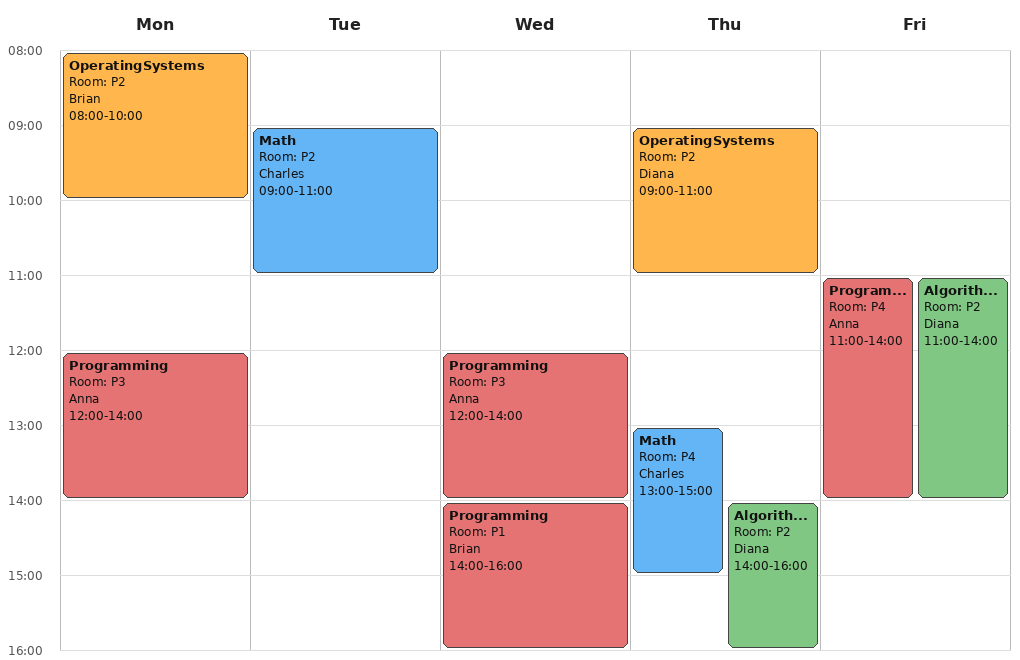

In [ ]:
problem = ProblemData("Classes.txt", "Classrooms.txt", "Teachers.txt")
print(f"{problem.n} lectures, {problem.num_classrooms} rooms, {problem.num_teachers} teachers, {problem.num_slots} slots")

snapshots = []          # (generation, best gene, fitness) 'stops' recorded during the run

ga = pygad.GA(
    num_generations=500,
    num_parents_mating=20,
    sol_per_pop=100,
    num_genes=3 * problem.n,
    gene_type=int,
    gene_space=problem.gene_space(),
    fitness_func=make_fitness_func(problem),
    parent_selection_type="tournament",
    K_tournament=4,
    keep_elitism=5,
    crossover_type="uniform",
    mutation_type="random",
    mutation_percent_genes=10,
    stop_criteria=["reach_1.0"],
    random_seed=42,
    on_generation=make_snapshot_callback(snapshots, every=1),   # a stop every 5 generations
)
ga.run()

solution, fit, _ = ga.best_solution()
best = Schedule.from_gene(solution, problem)
print("fitness:", fit, "| penalty:", best.calculate_penalty())
print("breakdown:", best.penalty_breakdown())
best.display_schedule()

# --- evolution animation: first stop -> ... -> final best schedule ---
if not snapshots or snapshots[-1][0] != ga.generations_completed:
    snapshots.append((ga.generations_completed, np.array(solution, dtype=int), float(fit)))
print(f"{len(snapshots)} stops recorded")
display(IPyImage(data=snapshots_to_gif(problem, snapshots), format="gif"))